## **The Dropout Knob: How MUCH is Too Much?**

*Is the network actually learning, or just memorizing? We will turn the knob to find out.*

Before diving into technicalities, let us first define regularization. The Cambridge Dictionary defines it as

>*"the act of changing a situation or system so that it follows rules or is based on reason."*

Let us think about that. A rule stops a system from going wild.

In data science, the International Business Machines Corporation (IBM) describes it as

> *"a set of methods for reducing overfitting in machine learning models. Typically, regularization trades a marginal decrease in training accuracy for increased generalizability."*

Notice how these two definitions actually link? Both talk about setting rules to keep the system from chaos and help it learn.

Still not getting the hang of it?  Worry not! Let us put it this way:

> **Student A** is brilliant at memorizing what is on its past papers—word for word—perfect on those papers, BUT lost when the real exam is worded differently.

> **Student B** then learns the underlying ideas—slightly less perfect on past papers, but solid on the real exam.

Obviously, if we understand it, Regularization is the set of rules that pushes it to behave like **Student B**—learning the pattern and not the exact answers.

With regularization in place, let us dive deep into one of its techniques: “The Dropout Knob.”

### **What is a Dropout Knob?**

It is not really called a knob; I chose to call it that because it functions like one. We already knew that Dropout is one of Regularization’s techniques, but techniques to what?

It helps overcome overfitting in a neural network and also helps avoid relying on most of the neurons, which can lead to ‘memorizing’ the training data; in simpler terms, it avoids being like **Student A.**

However, before we proceed, do we know what overfitting and underfitting are?

> **Overfitting** is like **Student A**, it performs with high accuracy on training data (past papers) but poorly on unseen data because it memorizes instead of generalizing, which is what performs better on unseen data.

> **Underfitting:** it performs poorly on both training and testing data because it reduces neurons too much, so it fails to capture important patterns in the data.

Now that we have learned the basics, we are about to explore what dropout is in actual scenarios; let us compare it across knobs, and by knobs I mean comparing it with other switches.

Let us First look at an example where we apply no Drropouts at all compared to a generalized one, like student A and Student B!

### **Import Libraries**

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

**No Dropout vs With Dropout**

These `dropout_p` values are what we call our knob on the neural network. We can adjust how much of the network is forced to "forget" during training. The value p is the setting on that knob: it represents the fraction of neurons we randomly switch off.

To see the effect, we need to train two separate models with everything kept identical (same data, same seed, same epochs), changing only the knob setting:

* Run A (No Dropout): We set p = 0.0, meaning the knob is off. This is our baseline (Student A).
* Run B (With Dropout): We set p = 0.5, meaning we randomly switch off 50% of the neurons in the dense layer. This is our regularized model (Student B).

In [8]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Run A: no dropout
tl_none, vl_none, va_none = train_model(dropout_p=0.0, epochs=25)

# Run B: dropout 0.5
tl_drop, vl_drop, va_drop = train_model(dropout_p=0.5, epochs=25)

p=0.0 | epoch  5 | train 0.521 | val 0.575 | val acc 79.5%
p=0.0 | epoch 10 | train 0.321 | val 0.490 | val acc 83.5%
p=0.0 | epoch 15 | train 0.244 | val 0.531 | val acc 84.2%
p=0.0 | epoch 20 | train 0.175 | val 0.530 | val acc 84.2%
p=0.0 | epoch 25 | train 0.114 | val 0.601 | val acc 83.8%
p=0.5 | epoch  5 | train 0.675 | val 0.610 | val acc 77.0%
p=0.5 | epoch 10 | train 0.503 | val 0.491 | val acc 84.2%
p=0.5 | epoch 15 | train 0.405 | val 0.542 | val acc 82.5%
p=0.5 | epoch 20 | train 0.310 | val 0.554 | val acc 81.2%
p=0.5 | epoch 25 | train 0.265 | val 0.509 | val acc 84.2%


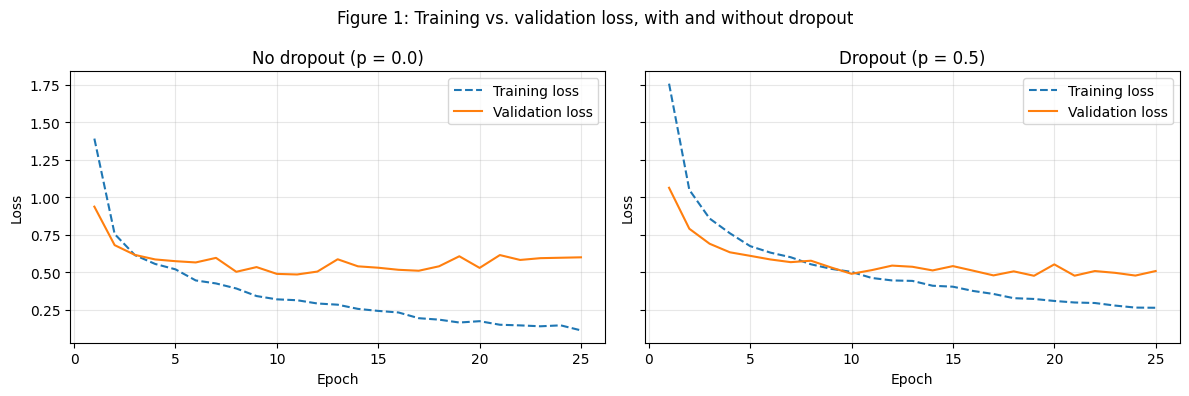

In [9]:
epochs = range(1, len(tl_none) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, tl, vl, title in [
    (axes[0], tl_none, vl_none, "No dropout (p = 0.0)"),
    (axes[1], tl_drop, vl_drop, "Dropout (p = 0.5)"),
]:
    ax.plot(epochs, tl, linestyle='--', color='tab:blue',  label='Training loss')
    ax.plot(epochs, vl, linestyle='-',  color='tab:orange', label='Validation loss')
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle("Figure 1: Training vs. validation loss, with and without dropout")
plt.tight_layout()
plt.savefig("fig1_dropout_ab.png", dpi=150, bbox_inches='tight')
plt.show()

Here, we can observe that our `left panel (p = 0.0)` looks like **Student A**: the training loss (dashed line) drops toward zero, meaning the network is memorizing the training images perfectly. However, the validation loss (solid line) stops improving and starts rising after epoch 10. This is overfitting, just like **Student A** failing the real exam after memorizing past papers and not really learning.

Now look at the `right panel (p = 0.5)` that served as our **Student B** this time: the two lines are much closer together. The training loss stays higher because making the network forget (dropout) makes training harder. But the validation loss stays stable and low. This network is actually learning the underlying pattern—just like **Student B**.

### **The Knob**

In [10]:
p_values = [0.0, 0.2, 0.5, 0.8]

results = {}
for p in p_values:
    results[p] = train_model(dropout_p=p, epochs=25)

p=0.0 | epoch  5 | train 0.453 | val 0.540 | val acc 80.0%
p=0.0 | epoch 10 | train 0.294 | val 0.563 | val acc 80.8%
p=0.0 | epoch 15 | train 0.210 | val 0.549 | val acc 84.5%
p=0.0 | epoch 20 | train 0.180 | val 0.554 | val acc 84.0%
p=0.0 | epoch 25 | train 0.156 | val 0.689 | val acc 79.5%
p=0.2 | epoch  5 | train 0.557 | val 0.572 | val acc 80.2%
p=0.2 | epoch 10 | train 0.386 | val 0.530 | val acc 81.2%
p=0.2 | epoch 15 | train 0.274 | val 0.478 | val acc 85.0%
p=0.2 | epoch 20 | train 0.200 | val 0.482 | val acc 84.5%
p=0.2 | epoch 25 | train 0.163 | val 0.544 | val acc 85.5%
p=0.5 | epoch  5 | train 0.622 | val 0.592 | val acc 81.0%
p=0.5 | epoch 10 | train 0.468 | val 0.522 | val acc 83.2%
p=0.5 | epoch 15 | train 0.369 | val 0.488 | val acc 85.0%
p=0.5 | epoch 20 | train 0.312 | val 0.508 | val acc 84.2%
p=0.5 | epoch 25 | train 0.244 | val 0.493 | val acc 82.8%
p=0.8 | epoch  5 | train 1.094 | val 0.726 | val acc 79.5%
p=0.8 | epoch 10 | train 0.853 | val 0.587 | val acc 80.

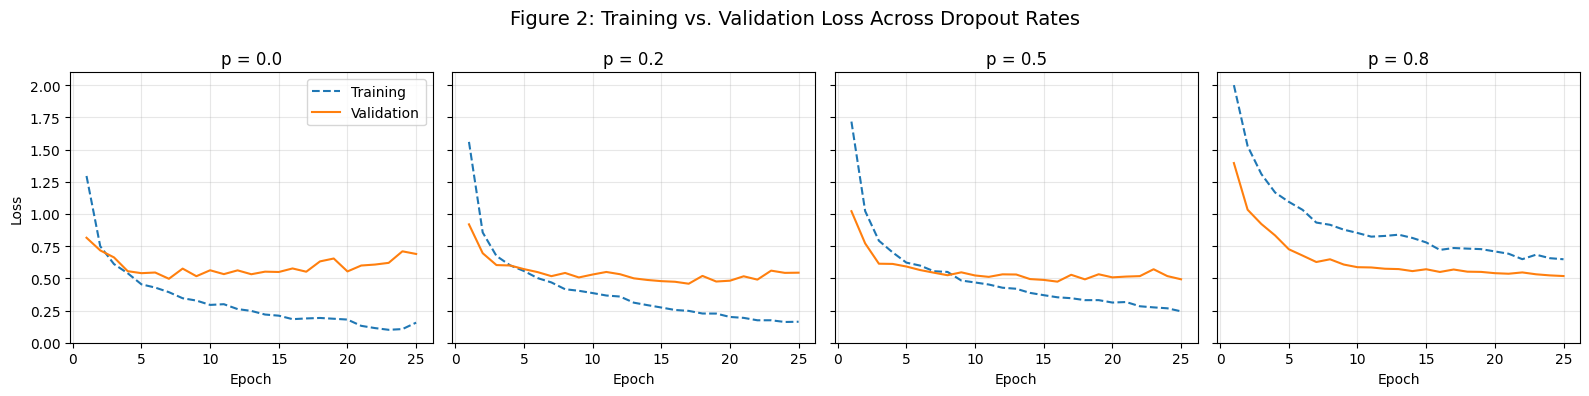

In [11]:
epochs = range(1, 26)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

for ax, p in zip(axes, p_values):
    tl, vl, va = results[p]

    ax.plot(epochs, tl, linestyle='--', color='tab:blue', label='Training')
    ax.plot(epochs, vl, linestyle='-', color='tab:orange', label='Validation')

    ax.set_title(f"p = {p}")
    ax.set_xlabel("Epoch")
    ax.set_ylim(0, 2.1)
    ax.grid(alpha=0.3)

    if p == 0.0:
        ax.set_ylabel("Loss")
        ax.legend()

fig.suptitle("Figure 2: Training vs. Validation Loss Across Dropout Rates", fontsize=14)
plt.tight_layout()
plt.savefig("fig2_dropout_panels.png", dpi=150, bbox_inches='tight')
plt.show()

Now, we are comparing different settings on the dropout knob to see how they affect overfitting and underfitting. We will sweep the value of p across four settings: 0.0, 0.2, 0.5, and 0.8.

The code below runs the same training loop for each setting and saves the results. (Notice that we keep the data, epochs, and seed identical—we only change p!)